# Smart Home Energy Consumption — Regression Modelling

**Goal:** predict `Energy Consumption (kWh)` for a single appliance reading from the appliance type, time, date, weather and household features.

**Dataset:** Kaggle *Smart Home Energy Consumption* (`data/smart_home_energy_consumption_large.csv`) — 100,000 rows × 8 columns, no missing values. See `outputs/data_dictionary.md` for the full column description.

**Workflow**
1. Load and inspect the data
2. Feature engineering — drop `Home ID`, extract `hour`, `month`, `day_of_week`
3. One-hot encode `Appliance Type` and `Season`
4. 80/20 train–test split (`random_state=42`)
5. Train four regressors: Linear, Polynomial (degree 2), Decision Tree, Random Forest (trees tuned with `GridSearchCV`)
6. Evaluate with MAE, MSE, RMSE and R², compare in a table
7. Visualise results; every plot is saved to `outputs/`

## 1. Setup

Import libraries, fix the random seed for reproducibility and define paths. All figures are written to `outputs/` so they can be reused in the report.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "smart_home_energy_consumption_large.csv"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

# Consistent, colour-blind-safe colours: one fixed colour per model across every plot
MODEL_COLORS = {
    "Linear Regression": "#2a78d6",
    "Polynomial Regression (deg 2)": "#eb6834",
    "Decision Tree": "#1baf7a",
    "Random Forest": "#6250d6",
}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#0b0b0b",
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})

def save(fig, name):
    path = OUT_DIR / name
    fig.savefig(path)
    print(f"Saved {path.relative_to(ROOT)}")

## 2. Load and inspect the data

We check shape, dtypes, missing values and duplicates before doing anything else. The target is **continuous** (kWh), so this is a **regression** problem.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
df.info()
df.head()

Shape: (100000, 8)
Missing values: 0 | Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Home ID                   100000 non-null  int64  
 1   Appliance Type            100000 non-null  str    
 2   Energy Consumption (kWh)  100000 non-null  float64
 3   Time                      100000 non-null  str    
 4   Date                      100000 non-null  str    
 5   Outdoor Temperature (°C)  100000 non-null  float64
 6   Season                    100000 non-null  str    
 7   Household Size            100000 non-null  int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 6.1 MB


,Home ID,Appliance Type,Energy Consumption (kWh),Time,Date,Outdoor Temperature (°C),Season,Household Size
0,94,Fridge,0.20,21:12,2023-12-02,-1.0,Fall,2
1,435,Oven,0.23,20:11,2023-08-06,31.1,Summer,5
2,466,Dishwasher,0.32,06:39,2023-11-21,21.3,Fall,3
3,496,Heater,3.92,21:56,2023-01-21,-4.2,Winter,1
4,137,Microwave,0.44,04:31,2023-08-26,34.5,Summer,5


In [3]:
TARGET = "Energy Consumption (kWh)"
df[TARGET].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
Energy Consumption (kWh),100000.0,1.499952,1.181176,0.1,0.59,1.23,1.87,5.0


### 2.1 Target distribution and the effect of appliance type

The histogram shows how energy values are spread; the box plot shows consumption per appliance. The data dictionary notes that **appliance type is the main driver** — heaters and air conditioners use far more energy than fridges.

Saved outputs/01_target_distribution.png


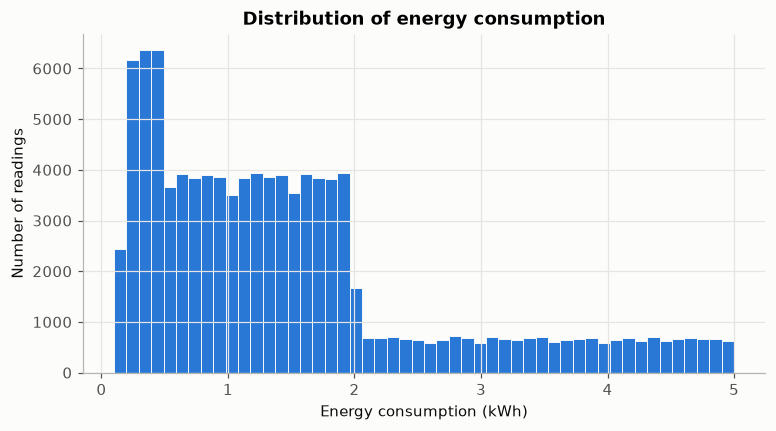

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df[TARGET], bins=50, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.6)
ax.set(title="Distribution of energy consumption", xlabel="Energy consumption (kWh)", ylabel="Number of readings")
save(fig, "01_target_distribution.png"); plt.show()

Saved outputs/02_energy_by_appliance.png


/var/folders/lw/gty9_7nn2ws8drnkj46f7rp80000gn/T/ipykernel_18418/541556458.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([df.loc[df["Appliance Type"] == a, TARGET] for a in order],


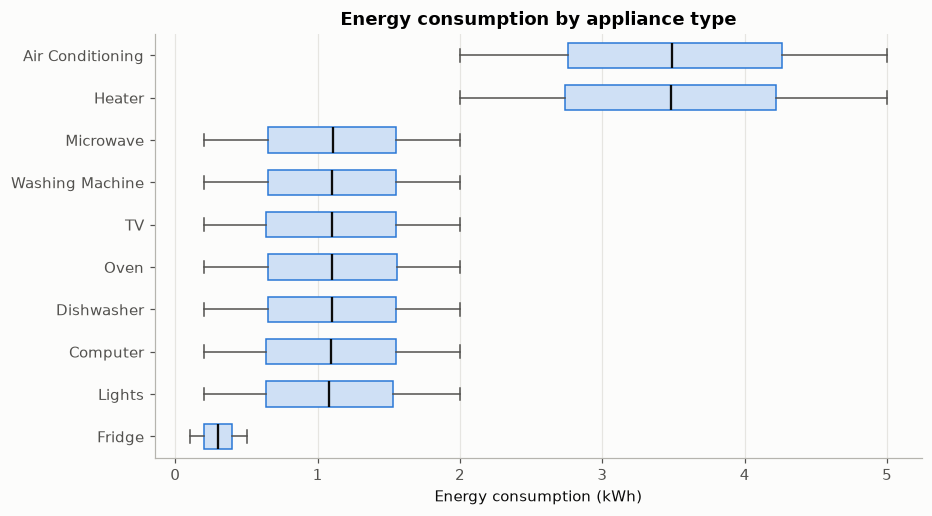

In [5]:
order = df.groupby("Appliance Type")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([df.loc[df["Appliance Type"] == a, TARGET] for a in order],
           vert=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#cfe0f5", edgecolor="#2a78d6"),
           medianprops=dict(color="#0b0b0b", linewidth=1.5),
           whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"))
ax.set_yticks(range(1, len(order) + 1), order)
ax.set(title="Energy consumption by appliance type", xlabel="Energy consumption (kWh)")
ax.grid(axis="y", visible=False)
save(fig, "02_energy_by_appliance.png"); plt.show()

## 3. Feature engineering

- **Drop `Home ID`** — it is an identifier, not a property of the household. Leaving it in would let tree models memorise IDs and the number has no meaningful order for linear models.
- **`Time` → `hour`** (0–23): captures time-of-day usage patterns.
- **`Date` → `month`** (1–12) and **`day_of_week`** (0 = Monday … 6 = Sunday): capture seasonal and weekly patterns.
- The raw `Time` and `Date` strings are then dropped, since models need numbers.

In [6]:
data = df.drop(columns=["Home ID"]).copy()

data["hour"] = pd.to_datetime(data["Time"], format="%H:%M").dt.hour
dates = pd.to_datetime(data["Date"], format="%Y-%m-%d")
data["month"] = dates.dt.month
data["day_of_week"] = dates.dt.dayofweek
data = data.drop(columns=["Time", "Date"])

data.head()

/var/folders/lw/gty9_7nn2ws8drnkj46f7rp80000gn/T/ipykernel_18418/176500185.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["day_of_week"] = dates.dt.dayofweek


,Appliance Type,Energy Consumption (kWh),Outdoor Temperature (°C),Season,Household Size,hour,month,day_of_week
0,Fridge,0.20,-1.0,Fall,2,21,12,5
1,Oven,0.23,31.1,Summer,5,20,8,6
2,Dishwasher,0.32,21.3,Fall,3,6,11,1
3,Heater,3.92,-4.2,Winter,1,21,1,5
4,Microwave,0.44,34.5,Summer,5,4,8,5


### 3.1 Correlation check on the numeric features

A quick correlation matrix shows how strongly each numeric feature moves with the target. Values near 0 mean almost no linear relationship.

Saved outputs/03_correlation_heatmap.png


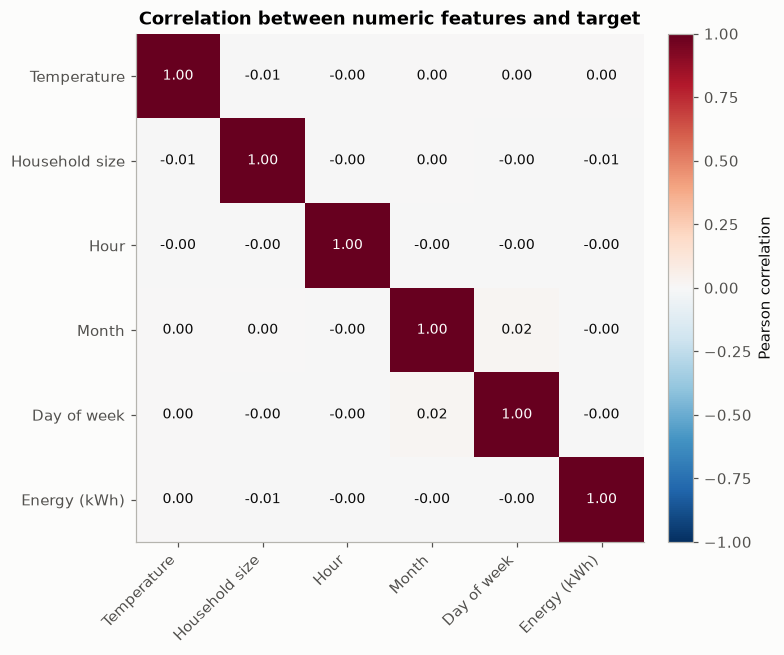

In [7]:
num_cols = ["Outdoor Temperature (°C)", "Household Size", "hour", "month", "day_of_week", TARGET]
corr = data[num_cols].corr()
labels = ["Temperature", "Household size", "Hour", "Month", "Day of week", "Energy (kWh)"]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="#fcfcfb" if abs(corr.iloc[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title("Correlation between numeric features and target")
save(fig, "03_correlation_heatmap.png"); plt.show()

## 4. One-hot encoding

`Appliance Type` (10 values) and `Season` (4 values) are **nominal** categories — there is no natural order, so label-encoding them as 0, 1, 2 … would invent a fake ranking. One-hot encoding creates one binary column per category.

We use `drop_first=True` to avoid the **dummy-variable trap**: with an intercept, the full set of dummies is perfectly collinear (they always sum to 1). The dropped category becomes the baseline that the other coefficients are compared against. Tree models are unaffected by this choice.

In [8]:
data_enc = pd.get_dummies(data, columns=["Appliance Type", "Season"], drop_first=True, dtype=int)

X = data_enc.drop(columns=[TARGET])
y = data_enc[TARGET]
print("Feature matrix:", X.shape)
print(list(X.columns))

Feature matrix: (100000, 17)
['Outdoor Temperature (°C)', 'Household Size', 'hour', 'month', 'day_of_week', 'Appliance Type_Computer', 'Appliance Type_Dishwasher', 'Appliance Type_Fridge', 'Appliance Type_Heater', 'Appliance Type_Lights', 'Appliance Type_Microwave', 'Appliance Type_Oven', 'Appliance Type_TV', 'Appliance Type_Washing Machine', 'Season_Spring', 'Season_Summer', 'Season_Winter']


## 5. Train–test split (80/20)

We hold out 20% of the rows as a **test set** the models never see during training or tuning. `random_state=42` makes the split reproducible. All hyperparameter tuning below uses cross-validation **inside the training set only**, so the test score is an honest estimate of performance on new data.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")

Train: 80,000 rows | Test: 20,000 rows


### 5.1 Evaluation helper

Each model is scored on the test set with four metrics:

| Metric | Meaning | Better |
|---|---|---|
| **MAE** | average absolute error, in kWh | lower |
| **MSE** | average squared error — punishes large mistakes more | lower |
| **RMSE** | √MSE, back in kWh so it is easy to interpret | lower |
| **R²** | share of the target's variance the model explains (1 = perfect, 0 = no better than predicting the mean) | higher |

We also record **train R²** to spot overfitting (a large gap between train and test R²).

In [10]:
results, predictions, fitted = [], {}, {}

def evaluate(name, model, fit_seconds):
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    row = {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": float(np.sqrt(mse)),
        "R²": r2_score(y_test, pred),
        "Train R²": r2_score(y_train, model.predict(X_train)),
        "Fit time (s)": fit_seconds,
    }
    results.append(row); predictions[name] = pred; fitted[name] = model
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})

## 6. Model 1 — Linear Regression

Linear regression fits a straight-line (hyperplane) relationship: `y = b0 + b1·x1 + … + bn·xn`, choosing coefficients that minimise squared error.

The numeric features have very different scales (temperature −10…40, hour 0…23, dummies 0/1), so we put a **`StandardScaler`** in front of the model inside a `Pipeline`. The pipeline guarantees the scaler is fitted on the training data only — no information from the test set leaks in.

In [11]:
lin_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
t0 = time.time(); lin_reg.fit(X_train, y_train)
evaluate("Linear Regression", lin_reg, time.time() - t0)

{'Model': 'Linear Regression', 'MAE': 0.476, 'MSE': 0.3411, 'RMSE': 0.584, 'R²': 0.7575, 'Train R²': 0.7553, 'Fit time (s)': 0.0215}


## 7. Model 2 — Polynomial Regression (degree 2)

Polynomial regression is still linear regression, but on **expanded features**: `PolynomialFeatures(degree=2)` adds every squared term (e.g. `hour²`) and every pairwise interaction (e.g. `temperature × Appliance_Heater`). This lets the model capture curved relationships and interactions such as "heaters use more when it's cold".

Scaling first keeps the squared terms numerically well-behaved. With 17 input features this produces 170 columns (17 original + 17 squares + 136 pairwise interactions).

In [12]:
poly_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression()),
])
t0 = time.time(); poly_reg.fit(X_train, y_train)
print("Polynomial feature count:", poly_reg.named_steps["poly"].n_output_features_)
evaluate("Polynomial Regression (deg 2)", poly_reg, time.time() - t0)

Polynomial feature count: 170
{'Model': 'Polynomial Regression (deg 2)', 'MAE': 0.476, 'MSE': 0.341, 'RMSE': 0.5839, 'R²': 0.7576, 'Train R²': 0.7556, 'Fit time (s)': 0.2926}


## 8. Model 3 — Decision Tree (tuned with GridSearchCV)

A decision tree splits the data with yes/no questions (e.g. *"Is the appliance a heater?"*) and predicts the average target in each final leaf. Trees handle non-linear effects and interactions automatically and **don't need feature scaling**.

An unrestricted tree grows until every leaf is pure and badly **overfits**. We tune two complexity controls with **`GridSearchCV`** (5-fold cross-validation on the training set, scored by RMSE):

- `max_depth` — how many questions deep the tree may go
- `min_samples_leaf` — minimum rows in each leaf (larger = smoother predictions)

In [13]:
dt_grid = {
    "max_depth": [3, 5, 8, 12, 16, None],
    "min_samples_leaf": [1, 10, 50, 200],
}
dt_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    dt_grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
t0 = time.time(); dt_search.fit(X_train, y_train)
print("Best params:", dt_search.best_params_)
print(f"Best CV RMSE: {-dt_search.best_score_:.4f}")
evaluate("Decision Tree", dt_search.best_estimator_, time.time() - t0)

Best params: {'max_depth': 12, 'min_samples_leaf': 200}
Best CV RMSE: 0.5864
{'Model': 'Decision Tree', 'MAE': 0.4769, 'MSE': 0.3434, 'RMSE': 0.586, 'R²': 0.7559, 'Train R²': 0.7572, 'Fit time (s)': 3.6716}


### 8.1 How tree depth affects error

The plot below shows mean cross-validated RMSE for each `max_depth`, one line per `min_samples_leaf`. Error typically falls at first (tree learns the appliance split), then rises again for deep trees with small leaves (overfitting to noise).

Saved outputs/04_decision_tree_tuning.png


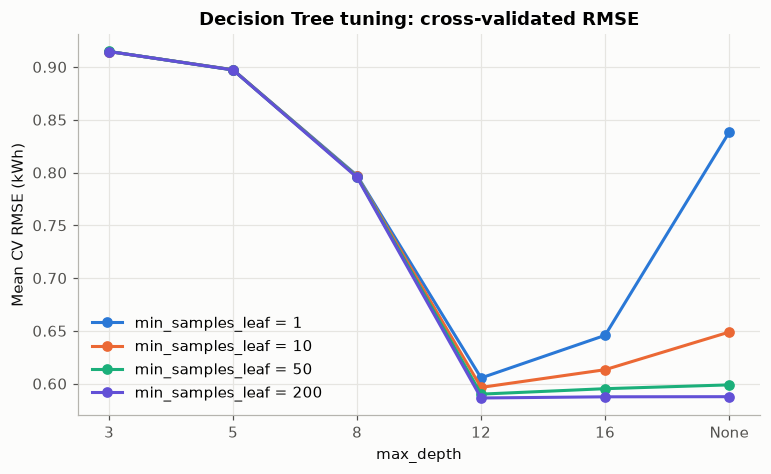

In [14]:
cv = pd.DataFrame(dt_search.cv_results_)
cv["depth"] = cv["param_max_depth"].apply(lambda d: "None" if d is None or pd.isna(d) else str(int(d)))
cv["rmse"] = -cv["mean_test_score"]
depth_order = [str(d) if d is not None else "None" for d in dt_grid["max_depth"]]
leaf_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

fig, ax = plt.subplots(figsize=(8, 4.5))
for color, leaf in zip(leaf_colors, dt_grid["min_samples_leaf"]):
    sub = cv[cv["param_min_samples_leaf"] == leaf].set_index("depth").loc[depth_order]
    ax.plot(depth_order, sub["rmse"], marker="o", markersize=6, linewidth=2, color=color,
            label=f"min_samples_leaf = {leaf}")
ax.set(title="Decision Tree tuning: cross-validated RMSE", xlabel="max_depth", ylabel="Mean CV RMSE (kWh)")
ax.legend(frameon=False)
save(fig, "04_decision_tree_tuning.png"); plt.show()

## 9. Model 4 — Random Forest (tuned with GridSearchCV)

A random forest trains many decision trees, each on a **bootstrap sample** of the rows and a random subset of features at each split, then **averages** their predictions. Averaging many decorrelated trees reduces variance, so a forest usually overfits much less than a single tree.

Forests are expensive to train, so the grid is kept compact and we use 3-fold cross-validation:

- `n_estimators` — number of trees
- `max_depth` — depth limit per tree
- `min_samples_leaf` — minimum rows per leaf

In [15]:
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, None],
    "min_samples_leaf": [5, 20],
}
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    rf_grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=1,
)
t0 = time.time(); rf_search.fit(X_train, y_train)
print("Best params:", rf_search.best_params_)
print(f"Best CV RMSE: {-rf_search.best_score_:.4f}")
evaluate("Random Forest", rf_search.best_estimator_, time.time() - t0)

Best params: {'max_depth': 12, 'min_samples_leaf': 20, 'n_estimators': 200}
Best CV RMSE: 0.5855
{'Model': 'Random Forest', 'MAE': 0.4764, 'MSE': 0.3419, 'RMSE': 0.5847, 'R²': 0.7569, 'Train R²': 0.7659, 'Fit time (s)': 43.478}


## 10. Results — model comparison table

All metrics are computed on the **held-out 20% test set**. The table is also saved to `outputs/model_metrics.csv`.

In [16]:
metrics = pd.DataFrame(results).set_index("Model")
metrics.to_csv(OUT_DIR / "model_metrics.csv", float_format="%.4f")
print("Saved outputs/model_metrics.csv")
metrics.style.format({"MAE": "{:.4f}", "MSE": "{:.4f}", "RMSE": "{:.4f}", "R²": "{:.4f}",
                      "Train R²": "{:.4f}", "Fit time (s)": "{:.1f}"}) \
       .highlight_min(subset=["MAE", "MSE", "RMSE"], color="#d6f0e4") \
       .highlight_max(subset=["R²"], color="#d6f0e4")

Saved outputs/model_metrics.csv


,MAE,MSE,RMSE,R²,Train R²,Fit time (s)
Model,,,,,,
Linear Regression,0.4760,0.3411,0.5840,0.7575,0.7553,0.0
Polynomial Regression (deg 2),0.4760,0.3410,0.5839,0.7576,0.7556,0.3
Decision Tree,0.4769,0.3434,0.5860,0.7559,0.7572,3.7
Random Forest,0.4764,0.3419,0.5847,0.7569,0.7659,43.5


### 10.1 What is the best R² we could hope for?

The data dictionary says energy use varies almost randomly *within* each appliance. If that's true, the best possible prediction is simply **the average consumption of that appliance type**. We compute this "appliance-mean" benchmark (means learned from the training set) to see how close our models get to the ceiling.

In [17]:
appl_train = df.loc[X_train.index, "Appliance Type"]
appl_test = df.loc[X_test.index, "Appliance Type"]
appliance_means = y_train.groupby(appl_train).mean()
ceiling_pred = appl_test.map(appliance_means)
ceiling_r2 = r2_score(y_test, ceiling_pred)
ceiling_rmse = np.sqrt(mean_squared_error(y_test, ceiling_pred))
print(f"Appliance-mean benchmark  →  R² = {ceiling_r2:.4f}, RMSE = {ceiling_rmse:.4f} kWh")

Appliance-mean benchmark  →  R² = 0.7575, RMSE = 0.5840 kWh


### 10.2 Metric comparison chart

One panel per metric so each keeps its own honest scale. The dashed line on the R² panel marks the appliance-mean benchmark.

Saved outputs/05_model_comparison.png


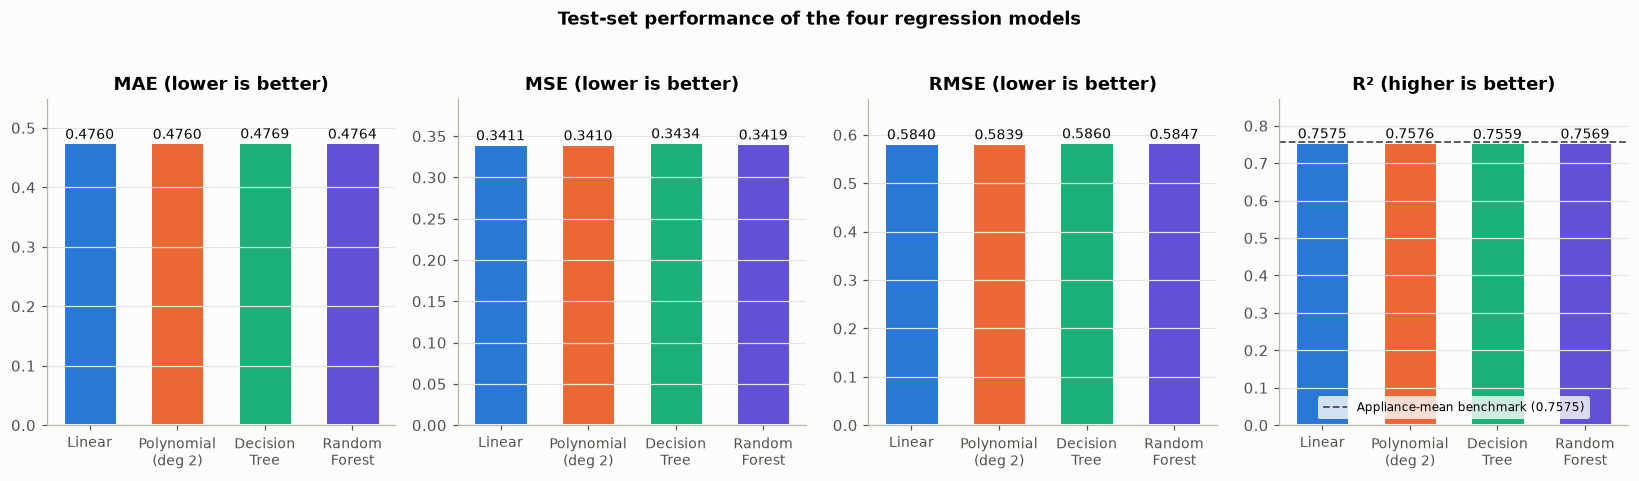

In [18]:
names = list(metrics.index)
short = ["Linear", "Polynomial\n(deg 2)", "Decision\nTree", "Random\nForest"]
colors = [MODEL_COLORS[n] for n in names]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
for ax, col in zip(axes, ["MAE", "MSE", "RMSE", "R²"]):
    vals = metrics[col].values
    bars = ax.bar(short, vals, color=colors, width=0.62, edgecolor="#fcfcfb", linewidth=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9, color="#0b0b0b")
    ax.set_title(col + (" (higher is better)" if col == "R²" else " (lower is better)"))
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=9)
    ax.set_ylim(0, max(vals) * 1.15)
axes[3].axhline(ceiling_r2, color="#52514e", linestyle="--", linewidth=1.2, label=f"Appliance-mean benchmark ({ceiling_r2:.4f})")
axes[3].legend(frameon=True, facecolor="#fcfcfb", edgecolor="none", loc="lower center", fontsize=8)
fig.suptitle("Test-set performance of the four regression models", fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "05_model_comparison.png"); plt.show()

## 11. Actual vs predicted

Each point is one test reading. A perfect model would put every point on the dashed diagonal. Because consumption is spread uniformly *within* each appliance, predictions form horizontal bands — the model predicts roughly the appliance average, while the true values scatter around it.

Saved outputs/06_actual_vs_predicted.png


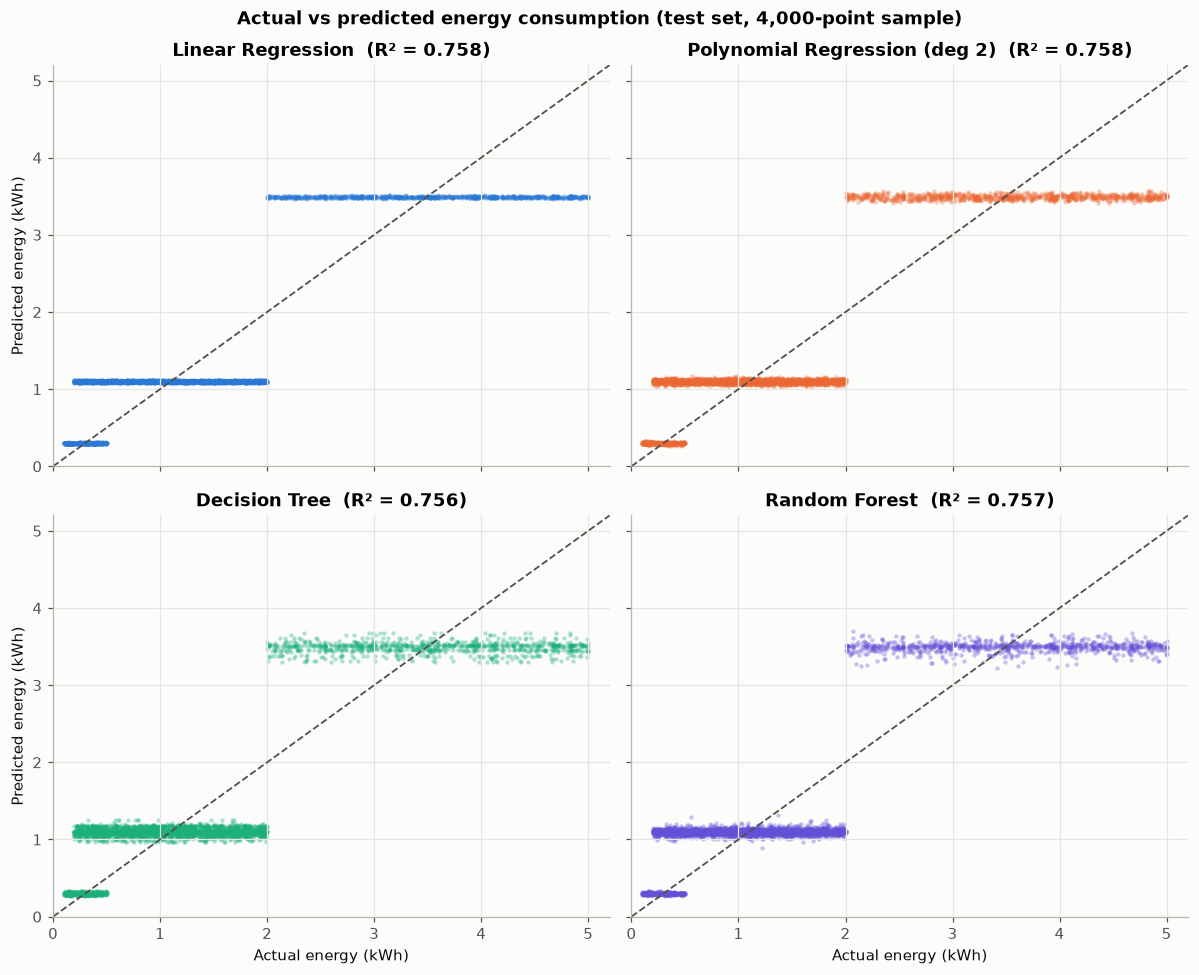

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(y_test), size=4000, replace=False)  # subsample so the plot stays readable

fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), names):
    ax.scatter(y_test.values[idx], predictions[name][idx], s=8, alpha=0.35, color=MODEL_COLORS[name], linewidths=0)
    ax.plot([0, 5.2], [0, 5.2], linestyle="--", color="#52514e", linewidth=1.2)
    ax.set_title(f"{name}  (R² = {metrics.loc[name, 'R²']:.3f})")
    ax.set_xlim(0, 5.2); ax.set_ylim(0, 5.2)
for ax in axes[1]: ax.set_xlabel("Actual energy (kWh)")
for ax in axes[:, 0]: ax.set_ylabel("Predicted energy (kWh)")
fig.suptitle("Actual vs predicted energy consumption (test set, 4,000-point sample)", fontweight="bold")
fig.tight_layout()
save(fig, "06_actual_vs_predicted.png"); plt.show()

## 12. Residual analysis

A residual is `actual − predicted`. Good residuals are centred on 0 with no pattern. Left: residuals against predicted values. Right: the residual distributions of all four models overlaid.

Saved outputs/07_residuals_vs_predicted.png


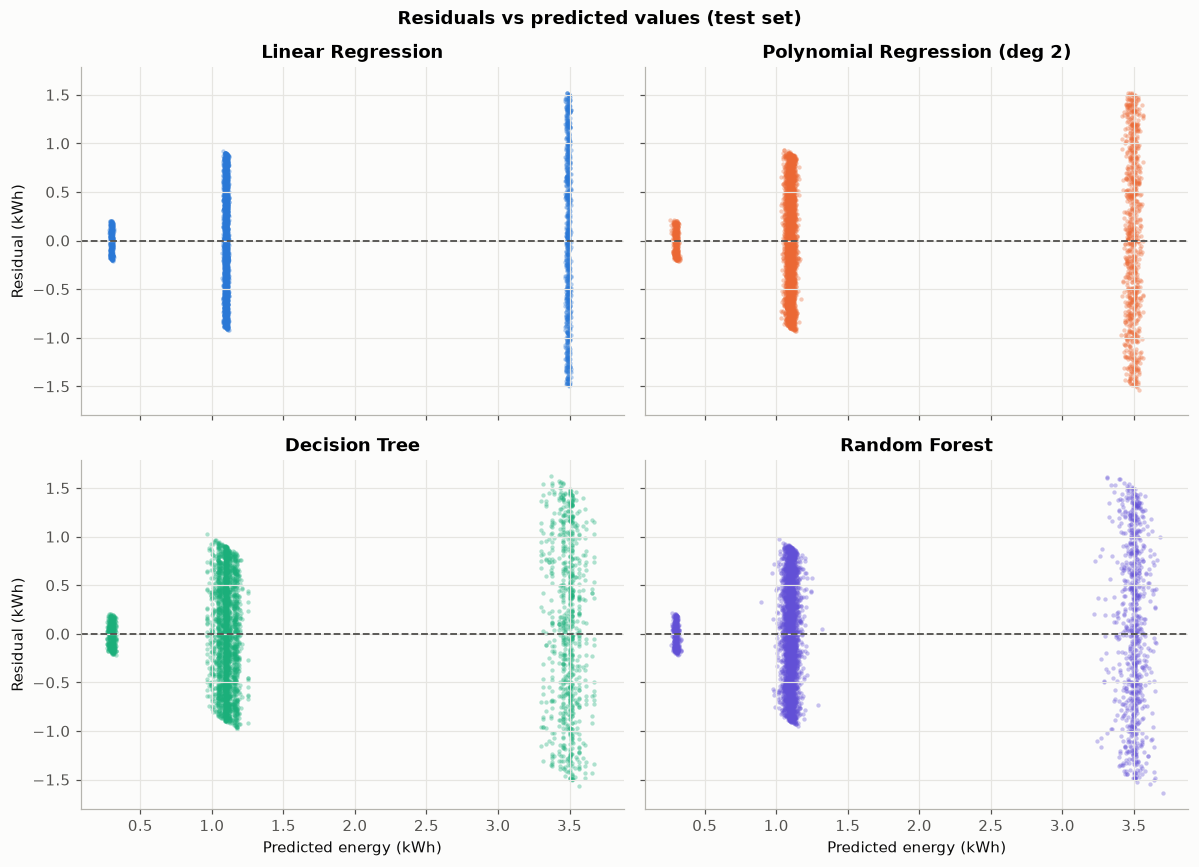

Saved outputs/08_residual_distribution.png


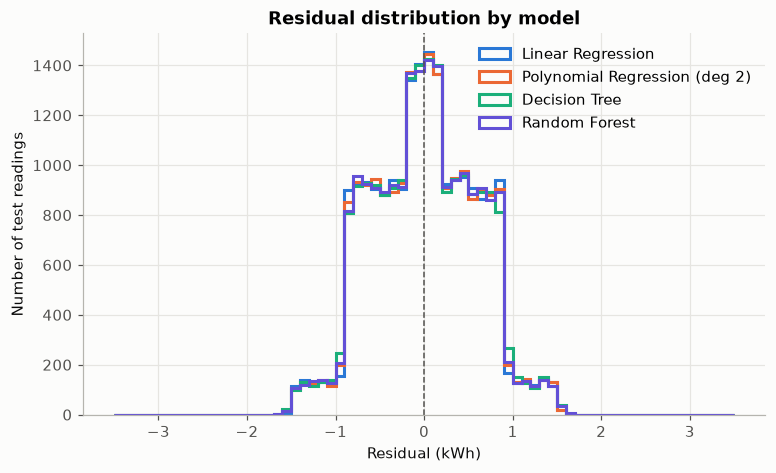

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), names):
    resid = y_test.values - predictions[name]
    ax.scatter(predictions[name][idx], resid[idx], s=8, alpha=0.35, color=MODEL_COLORS[name], linewidths=0)
    ax.axhline(0, color="#52514e", linestyle="--", linewidth=1.2)
    ax.set_title(name)
for ax in axes[1]: ax.set_xlabel("Predicted energy (kWh)")
for ax in axes[:, 0]: ax.set_ylabel("Residual (kWh)")
fig.suptitle("Residuals vs predicted values (test set)", fontweight="bold")
fig.tight_layout()
save(fig, "07_residuals_vs_predicted.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(-3.5, 3.5, 71)
for name in names:
    ax.hist(y_test.values - predictions[name], bins=bins, histtype="step", linewidth=2,
            color=MODEL_COLORS[name], label=name)
ax.axvline(0, color="#52514e", linestyle="--", linewidth=1)
ax.set(title="Residual distribution by model", xlabel="Residual (kWh)", ylabel="Number of test readings")
ax.legend(frameon=False)
save(fig, "08_residual_distribution.png"); plt.show()

## 13. Feature importance (tree models)

Tree-based models report how much each feature reduced prediction error across all splits (impurity-based importance). This tells us **which inputs the models actually rely on**.

*Note:* `Air Conditioning` (and `Season: Fall`) do not appear because they were the categories dropped by `drop_first=True`; they are the baseline. Trees separate AC/Heater from the rest mainly through the `Heater` column plus the other appliance dummies.

Saved outputs/09_feature_importance.png


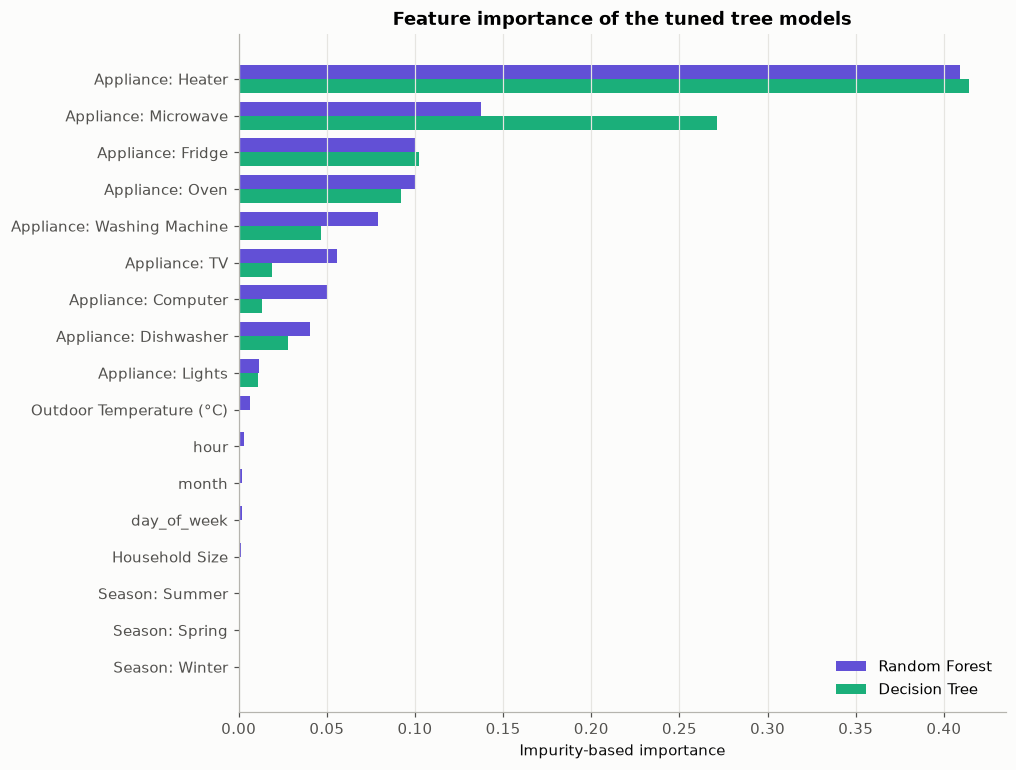

,Decision Tree,Random Forest
Appliance: Heater,0.414478,0.409345
Appliance: Microwave,0.271523,0.137666
Appliance: Fridge,0.102145,0.100718
Appliance: Oven,0.091773,0.100394
Appliance: Washing Machine,0.046581,0.078893
Appliance: TV,0.018757,0.055792
Appliance: Computer,0.013457,0.049917
Appliance: Dishwasher,0.028040,0.040625
Appliance: Lights,0.010791,0.011552
Outdoor Temperature (°C),0.000968,0.006491


In [21]:
def pretty(col):
    return col.replace("Appliance Type_", "Appliance: ").replace("Season_", "Season: ")

imp = pd.DataFrame({
    "Decision Tree": fitted["Decision Tree"].feature_importances_,
    "Random Forest": fitted["Random Forest"].feature_importances_,
}, index=[pretty(c) for c in X.columns]).sort_values("Random Forest")
imp.to_csv(OUT_DIR / "feature_importance.csv", float_format="%.5f")

fig, ax = plt.subplots(figsize=(9, 8))
y_pos = np.arange(len(imp))
h = 0.38
ax.barh(y_pos + h / 2, imp["Random Forest"], height=h, color=MODEL_COLORS["Random Forest"], label="Random Forest")
ax.barh(y_pos - h / 2, imp["Decision Tree"], height=h, color=MODEL_COLORS["Decision Tree"], label="Decision Tree")
ax.set_yticks(y_pos, imp.index)
ax.set(title="Feature importance of the tuned tree models", xlabel="Impurity-based importance")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save(fig, "09_feature_importance.png"); plt.show()
imp.sort_values("Random Forest", ascending=False).head(10)

## 14. Linear model coefficients

For the (scaled) linear model, each coefficient is the change in predicted kWh for a one-standard-deviation increase in that feature. Large coefficients on the appliance dummies and near-zero coefficients elsewhere confirm the same story as the tree importances.

Saved outputs/10_linear_coefficients.png


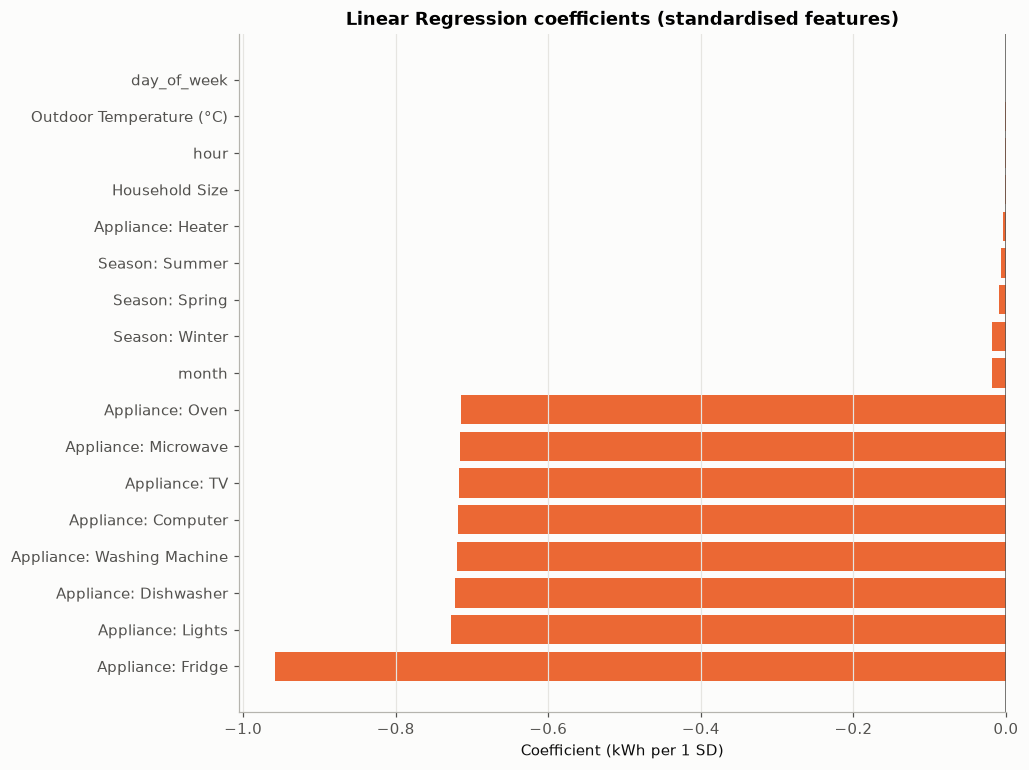

In [22]:
coefs = pd.Series(fitted["Linear Regression"].named_steps["model"].coef_,
                  index=[pretty(c) for c in X.columns]).sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(coefs.index, coefs.values,
        color=["#eb6834" if v < 0 else "#2a78d6" for v in coefs.values])
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Linear Regression coefficients (standardised features)", xlabel="Coefficient (kWh per 1 SD)")
ax.grid(axis="y", visible=False)
save(fig, "10_linear_coefficients.png"); plt.show()

## 15. Conclusions

In [23]:
best = metrics["R²"].idxmax()
print(f"Best model on the test set: {best}")
print(f"  R² = {metrics.loc[best, 'R²']:.4f} | RMSE = {metrics.loc[best, 'RMSE']:.4f} kWh | MAE = {metrics.loc[best, 'MAE']:.4f} kWh")
print(f"Appliance-mean benchmark R² = {ceiling_r2:.4f}")
print(f"Spread of test R² across all four models: {metrics['R²'].max() - metrics['R²'].min():.4f}")

Best model on the test set: Polynomial Regression (deg 2)
  R² = 0.7576 | RMSE = 0.5839 kWh | MAE = 0.4760 kWh
Appliance-mean benchmark R² = 0.7575
Spread of test R² across all four models: 0.0017


**Key findings**

1. **Appliance type explains almost all of the predictable variation.** Both tree importances and linear coefficients are dominated by the appliance dummies (especially Heater and Air Conditioning). Temperature, season, household size and time features contribute almost nothing.
2. **All four models land close to the appliance-mean benchmark (R² ≈ 0.75).** Once appliance type is one-hot encoded, even plain linear regression can represent "one average per appliance", so the extra flexibility of polynomial terms, trees and forests buys very little.
3. **The tuned trees avoid overfitting.** GridSearchCV chose constrained trees (limited depth / larger leaves); the small gap between train R² and test R² confirms they generalise. An unconstrained tree would memorise noise and score worse.
4. **The remaining ~25% of variance is noise with respect to the available features.** Within an appliance, consumption is close to uniformly random — a sign the dataset is synthetic. Better predictions would need richer data such as appliance power rating, usage duration, or real smart-meter readings.

**Saved outputs** (in `outputs/`): `model_metrics.csv`, `feature_importance.csv`, and plots `01`–`10`.